In [3]:
from sympy import*
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

## Model of System

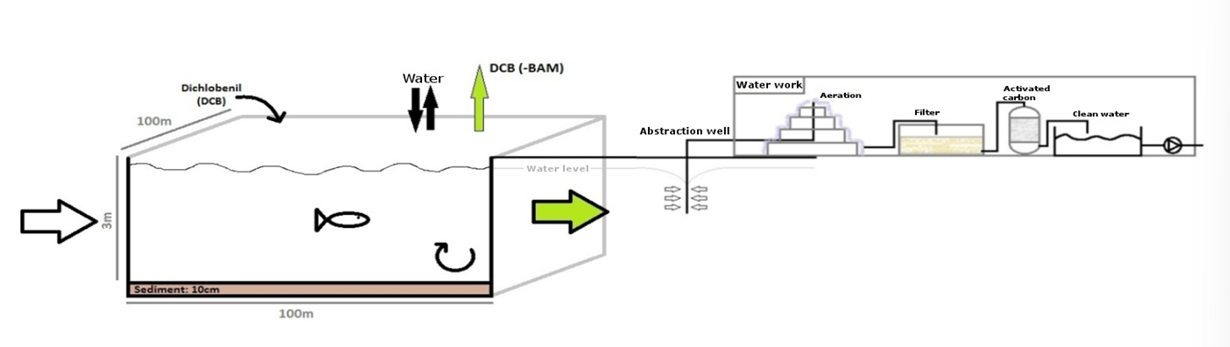

___

## 1. Concentration of DCB and BAM in the Lake

### A) Initial Concentration of DCB

$$ K_d = f_{oc}\cdot  K_{oc} $$

Based on $f_{oc}$ and description of environment we assume equation C in Figure 6.2 in the Compendium.

In [4]:
foc = 0.02
log_Kow_DCB = 2.7

#assume equation C in table 6.2 in compendium
a = 0.72
b = 0.49
Koc_DCB = 10**(a*log_Kow_DCB + b)

Kd_DCB = foc * Koc_DCB #l/kg
print(f"Kd(DCB): {Kd_DCB:.2f} L/kg")

Kd(DCB): 5.43 L/kg


Mass Balance for DCB: 
$$Mt = Cs \cdot Ms + Cw \cdot Mw$$

$K_d$ formula: $C_s = K_d \cdot C_w$

Additionally: $ M_w = V_w $

Substitute $C_s$ and Isolate for $C_w$
$$Cw = \frac{Mt}{Vw +Kd \cdot Ms} $$

In [5]:
V_lake = (100*100*3)*1e3 #l
m_DCB = 100*0.1 #kg
Vs = 100*100*0.1 #m3
bulk_dens = 1600 #kg/m3
Ms = Vs*bulk_dens #kg

Cw_DCB = m_DCB/(V_lake + Kd_DCB * Ms) #kg/l
print(f"Cw(DCB): {Cw_DCB:.2e} kg/L")

Cw(DCB): 2.58e-07 kg/L


___

### B) Material Balance for DCB

Assume Material balance equations for CMFR, we now need to find an expression for accumulation with 1. order decay.

$$ Accumulated = Inflow - Outflow + Net \ Transformation = Inflow - Outflow + Decay + Evaporation $$

$Accumulation \; [mol/s]$:

$$ Accum. = \frac{d(C_w M_w)}{dt} + \frac{d(C_s M_s)}{dt}$$

Since: $$C_s = K_d \cdot C_w, \quad M_w = V_w(L) $$

Then: $$ Accum. = \frac{d(C_w V_w)}{dt} + \frac{d(K_d C_w)}{dt}M_s$$

___

$Inflow \; [mol/s]$:

$$Inflow = Q_{in} \cdot C_{in}, \quad C_{in}=0 \rightarrow Inflow = 0 $$

___

$Outflow \; [mol/s)$:

$$ Outflow = Q_{out} \cdot C_{out} $$

Since: $$ U = \frac{Q}{A} \rightarrow Q = UA $$

Then: $$ Outflow = UAC_{out} $$

In [6]:
# flow out
U = 20/365
A_lake = 100*3
Q_out = (U*A_lake)*(365*24*60*60)**-1 #m3/s
print(f"Outflow: {Q_out:.2e} m3/s")

Outflow: 5.21e-07 m3/s


___

$Decay \; [days]$:

$$ Decay = rV $$

For first order decay:
$$ r = -k_1C $$

Then:
$$Decay = -k_1C(t)V_w$$

Derive k1 from half-time:
$$ t½ = \frac{\ln{2}}{k_1} \rightarrow k_1 = \frac{\ln{2}}{t½} $$

In [7]:
t_half = 128 #days

k1 = np.log(2)/t_half
print(f"k1: {k1:.2e}")

k1: 5.42e-03


___

$Evaporation \; [mol/s]$:

Evaporation flux formula:

$$J_{gl} = k_{gl}(C_s - C)$$

$$ C_s = 0, \quad C=C(t) $$

With given $K_H$ in provided Appendix $k_{gl}$ can be read in Figure 4.C.7 in the book:

$$ k_{gl} = 10^{-2} \ m \ hours^{-1} \rightarrow k_{gl} = 10^{-2} \cdot 24 = 0.24 \ m \ days^{-1} $$

To get a flux with mass per area per time we introduce evaporation area:

$$ Evaporation = -k_{gl}C(t)A_{surface}

___

$Complete \ Differential \ Equation \ for \ Concentration \ Over \ Time$:

$$ Accumulated = Inflow - Outflow + Net \ Transformation = Inflow - Outflow + Decay + Evaporation$$

$$\frac{d(C(t) V_w)}{dt} + \frac{d(K_d C(t))}{dt}M_s = 0 - UA_{out} C(t) + (-k_1C(t)V_w) + (-k_{gl}C(t)A_{surface}) $$

Simplify and isolate for concentration over time:
$$ \frac{dC_{DCB}}{dt} = C_{DCB}(t) \frac{ - UA_{Lake} - k1V_w - k_{gl}A_{surface}}{V_W + K_dM_s} $$

In [8]:
# define function
C_DCB = Function('C_DCB')

#define symbol
t = symbols('t')

A_lake = 100*3 #m2
A_overflade = 100*100 #m2
k_gl = 1e-2*24 #m/days
V_lake = 100*100*3 #m3
k1 = 0.0054 #per day
U = 20/365 #m/day
Kd_DCB = 5.433e-3 #m3

#insert function
di = Eq(diff(C_DCB(t),t),(-k_gl*A_overflade*C_DCB(t) - k1*V_lake*C_DCB(t) - U*A_lake*C_DCB(t)) / (V_lake + Kd_DCB*Ms))

#løs
Ct_DCB = dsolve(di, ics = {C_DCB(0):0.258}) #insert Cw in mg/L as limit
Ct_DCB

Eq(C_DCB(t), 0.258*exp(-0.0666387120126841*t))

___

### C) Mass Balance BAM

Disregard degradation due to BAM's very slow degradation rate, therefore irrelevant for assignment perspective of 90 days.

Disregard evaporation due to low Henry's Law Constant provided in appendix: 

$$K_{H(BAM)} = 1.22e-9$$

Disregard sorption as BAM is almost exclusively in the water phase:




$$ f_{w(BAM)} = \frac{C_w V_w}{C_wV_w + C_sV_s} = \frac{C_w V_w}{C_w V_w + K_d C_w V_s} = \frac{V_w}{V_w + K_d V_s}$$

Find $K_{d(BAM)}$

In [9]:
foc = 0.02
log_Kow_BAM = 0.77

#assume equation C table 6.2 in compendium
a = 0.72
b = 0.49
Koc_BAM = 10**(a*log_Kow_BAM + b)

Kd_BAM = foc * Koc_BAM #L/kg
print(f"Kd(BAM): {Kd_BAM:.2e} L/kg")

Kd(BAM): 2.22e-01 L/kg


In [10]:
fw_BAM = (V_lake)/(V_lake + Kd_BAM*Vs)
print(f"fw(BAM): {fw_BAM*100:.2f} %")

fw(BAM): 99.27 %


Material Balance BAM (degradation product):
$$ Accumulated = Net \ Transformation - Outflow = Produced - Outflow$$

$$ V_w\frac{dC_{BAM}}{dt} = k1C_{DCB}(t) - k_LC_{BAM}(t) $$

Isolate for differential of concentration over time:
$$ \frac{dC_{BAM}}{dt} = \frac{k1C_{DCB}(t)V_w - UAC_{BAM}(t)}{V_w} $$

In [11]:
A_overflade = 100*100 #m2
A_lake = 100*3 #m2
V_lake = 100*100*3 #m3
k1 = 0.0054 #days
U = 20/365 #m/day

C_BAM = Function('C_BAM')

t = symbols('t')

di = Eq(diff(C_BAM(t),t), (k1*Ct_DCB.rhs*V_lake -  U*A_lake*C_BAM(t))/V_lake)

Ct_BAM = dsolve(di, ics = {C_BAM(0):0})
Ct_BAM

Eq(C_BAM(t), -0.021080100402892*exp(-0.0666387120126841*t) + 0.021080100402892*exp(-0.000547945205479452*t))

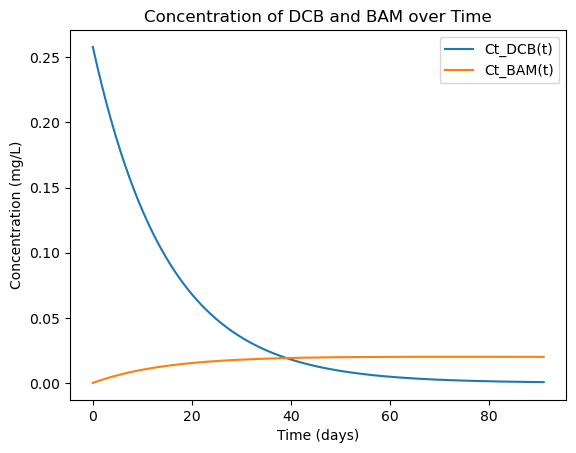

In [12]:
t = symbols('t', real=True)
Ct_DCB_fun = lambdify(t, Ct_DCB.rhs, 'numpy')
Ct_BAM_fun = lambdify(t, Ct_BAM.rhs, 'numpy')

t_vals = np.linspace(0, 91, 600)

plt.plot(t_vals, Ct_DCB_fun(t_vals), label="Ct_DCB(t)")
plt.plot(t_vals, Ct_BAM_fun(t_vals), label="Ct_BAM(t)")

plt.xlabel("Time (days)")
plt.ylabel("Concentration (mg/L)")
plt.title("Concentration of DCB and BAM over Time")
plt.legend()
plt.show()

Max Concentration BAM:

In [13]:
Cd_vals = Ct_BAM_fun(t_vals)

# Find max value and time
max_BAM = np.max(Cd_vals)
t_at_max = t_vals[np.argmax(Cd_vals)]

print(f"BAM max. conc.: {max_BAM:.2e} mg/L")
print(f"Time at BAM max. conc.: {t_at_max:.1f} days")

BAM max. conc.: 2.01e-02 mg/L
Time at BAM max. conc.: 72.6 days


___

#### D) Compare $LC_{50} / EC_{50}$ Values

In [14]:
tox_data = pd.DataFrame({
    "Species": ["Rainbow trout", "Fathead minnow", "Duckweed"],
    "Type": ['LC50', 'LC50', 'EC50'],
    "DCB LC50 / EC50 (mg/L)": [3.83, 3.98, 0.0279],
    "BAM LC50 / EC50 (mg/L)": [180, 496, 75]
})


tox_data["DCB Lim. Exceeded"] = (
    (tox_data["Type"] == "LC50") & (Cw_DCB*1e6 > tox_data["DCB LC50 / EC50 (mg/L)"]) |
    (tox_data["Type"] == "EC50") & (Cw_DCB*1e6 > tox_data["DCB LC50 / EC50 (mg/L)"])
)

tox_data["BAM Lim. Exceeded"] = (
    (tox_data["Type"] == "LC50") & (max_BAM > tox_data["BAM LC50 / EC50 (mg/L)"]) |
    (tox_data["Type"] == "EC50") & (max_BAM > tox_data["BAM LC50 / EC50 (mg/L)"])
)

for _, row in tox_data.iterrows():
    if row['BAM Lim. Exceeded']:
        print(f"BAM Limit {row['Type']} Exceeded for {row['Species']}")
    elif row['DCB Lim. Exceeded']:
        print(f"DCB Limit {row['Type']} Exceeded for {row['Species']}")

DCB Limit EC50 Exceeded for Duckweed


In [15]:
tox_data

,Species,Type,DCB LC50 / EC50 (mg/L),BAM LC50 / EC50 (mg/L),DCB Lim. Exceeded,BAM Lim. Exceeded
0,Rainbow trout,LC50,3.8300,180,False,False
1,Fathead minnow,LC50,3.9800,496,False,False
2,Duckweed,EC50,0.0279,75,True,False


## 2. At the Waterworks

### A) Inlet Concentration

$$ B_{inlet} = \frac{U_p}{Q}C_0 $$

In [16]:
Up = 6000 #m3 / year
Q = 3e5 #m3 / year
B_inlet = Up/Q*max_BAM
print(f"Inlet Concentration: {B_inlet*1e3:.1f} µg/L")

Inlet Concentration: 0.4 µg/L


___

### B) Sand Filter Retardation

$$ R = 1 + \frac{\rho _b}{\phi}K_d $$

find $K_{d(BAM)}$ as previously:

In [17]:
foc = 0.0011
log_Kow_BAM = 0.77

#assume equation D table 6.2 in compendium
a = 1.04
b = -0.84
Koc_BAM = 10**(a*log_Kow_BAM + b)

Kd_BAM = foc * Koc_BAM #L/kg
print(f"Kd(BAM): {Kd_BAM:.2e} L/kg")

Kd(BAM): 1.01e-03 L/kg


In [18]:
bulk_dens = 1300 #kg/m3
porosity = 0.5

R = 1 + bulk_dens / porosity * Kd_BAM*1e-3
print(f"R: {R:.2f}")

R: 1.00


___

### C) Cylinder Dimensions

Find Volume based on output of waterworks and residence time.

$$ Cylinder \; Geometry: \ d/h = 2 $$

$$ d = 2r \\
h=2d=2\cdot 2r = 4r \\
h = 4r
$$

$$V_{cylinder} = \pi r^2 4r = \pi 4r^3 $$

In [19]:
out_year = 3e5 #m3
res_time = 20 #min

out_min = out_year/(365*24*60) #m3/min.
V_cylinder = out_min*res_time #m3

print(f"Volume of cylinder: {V_cylinder:.2f} m3")

Volume of cylinder: 11.42 m3


In [20]:
r = symbols('r')
eq = Eq(V_cylinder, pi*4*r**3)
sol_r = solve(eq, r)[0]
print(f"r: {sol_r:.3f} m")

r: 0.968 m


Cylinder dimensions

In [21]:
d = 2*sol_r #m
h = 4*sol_r #m

print(f"Diameter: {d:.2f} m")
print(f"Height: {h:.2f} m")

Diameter: 1.94 m
Height: 3.87 m


___

### D) Change of Activated Carbon Filter

$\bold{Without \ Dispersion}$

Find retardation factor:

In [22]:
Kd_AC = 1.15*1e3 #m3/kg
bulk_dens = 0.42*1e3 #kg/m3
porosity = 0.5

R = 1 + (bulk_dens / porosity) * Kd_AC
print(f"R: {R}")

R: 966001.0


Seepage Velocity: $v_p = \frac{Q}{A \phi}$

Time before change of filter: $t_s = \frac{H}{v_s} = \frac{RH}{v_p}$

In [23]:
R = 966001
h = 3.8746 #m

Q = out_year/(365*24) #m3/hour
r = d/2 #m
A = (pi*r**2).evalf() #m2
porosity = 0.5

vp = Q/(A*porosity)
print(f"vp: {vp:.2f} m/s")

ts_hours = (R*h)/vp #hours
ts_year = ts_hours/24/365 #years
print(f"t: {ts_year:.1f} years")

vp: 23.24 m/s
t: 18.4 years


___

$\bold{With \ Dispersion}$

Dispersion model based on Eq. 6.24 in Compendium:

$$ F(x,t) = \frac{1}{2} \, \operatorname{erfc}\!\left( \frac{1 - \theta_R}{2 \left( \frac{\theta_R}{Pe} \right)^{1/2}} \right)
+ \frac{1}{2} e^{Pe} \cdot \operatorname{erfc}\!\left( \frac{1 + \theta_R}{2 \left( \frac{\theta_R}{Pe} \right)^{1/2}} \right) $$

Péclet Number: $Pe = \frac{v_p x}{D} $

Residence Time: $ \theta_R =\frac{\theta}{R} $

Dimensioneless Time: $ \theta = \frac{v_pt}{x} $

Breakthrough time t_s = 161041.4 hours = 18.38 years


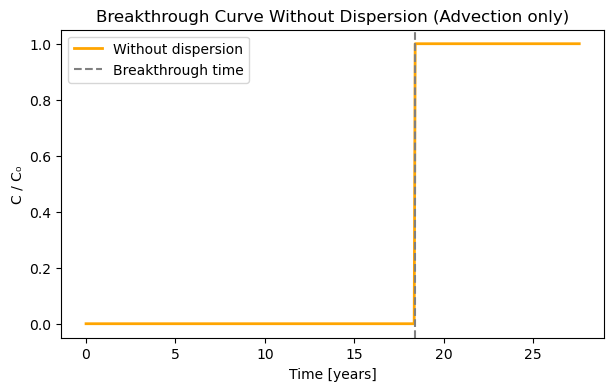

In [24]:
import numpy as np
import matplotlib.pyplot as plt

# Constants
R = 966001          # retardation factor
vp = 23.24165       # m/h
H = 3.8746          # m
C0 = 1.0            # dimensionless concentration (C/C0)

# Breakthrough time
t_breakthrough = (R * H) / vp  # h
print(f"Breakthrough time t_s = {t_breakthrough:.1f} hours = {t_breakthrough/24/365:.2f} years")

# t-axis
t_vals = np.linspace(0, t_breakthrough * 1.5, 500)

# Without Dispersion
C_vals = np.zeros_like(t_vals)
C_vals[t_vals >= t_breakthrough] = C0

# Plot
plt.figure(figsize=(7,4))
plt.plot(t_vals/24/365, C_vals, label="Without dispersion", color="orange", linewidth=2)
plt.axvline(t_breakthrough/24/365, color="gray", linestyle="--", label="Breakthrough time")
plt.xlabel("Time [years]")
plt.ylabel("C / C₀")
plt.title("Breakthrough Curve Without Dispersion (Advection only)")
plt.legend()
plt.show()

Peclets Number: 9.0030


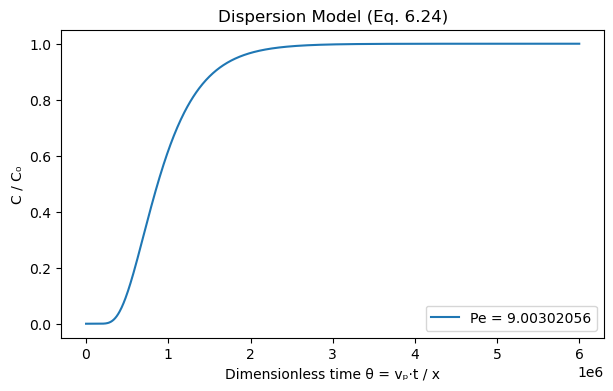

In [25]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import erfc

vp = 23.236 #m/h
epsilon = 10 #m2/h
h = 3.8746 #m
R = 966001

# Define time and dimensionless variables
t_vals = np.linspace(0.1, 1e6, 1000)    # time [h]
Theta = (vp * t_vals) / h               # dimensionless time
Theta_R = Theta / R                     # retardation-corrected time
Pe = vp * h / epsilon                   # Peclet number
print(f"Peclets Number: {Pe:.4f}")

# Dispersion model (Eq. 6.24)
def F_xt(Pe, Theta_R):
    term1 = 0.5 * erfc((1 - Theta_R) / (2 * np.sqrt(Theta_R / Pe)))
    term2 = 0.5 * np.exp(Pe) * erfc((1 + Theta_R) / (2 * np.sqrt(Theta_R / Pe)))
    return term1 + term2

# Compute F(x,t)
F_vals = F_xt(Pe, Theta_R)

# Plot
plt.figure(figsize=(7,4))
plt.plot(Theta, F_vals, label=f"Pe = {Pe}")
plt.xlabel("Dimensionless time θ = vₚ·t / x")
plt.ylabel("C / C₀")
plt.title("Dispersion Model (Eq. 6.24)")
plt.legend()
plt.show()

Péclet number = 9.01
Breakthrough time t_s = 18.38 years


C:\Users\mtloo\AppData\Local\Temp\ipykernel_23572\1421717663.py:24: RuntimeWarning: divide by zero encountered in divide
  term1 = 0.5 * erfc((1 - theta_R) / (2 * np.sqrt(theta_R / Pe)))
C:\Users\mtloo\AppData\Local\Temp\ipykernel_23572\1421717663.py:25: RuntimeWarning: divide by zero encountered in divide
  term2 = 0.5 * np.exp(Pe) * erfc((1 + theta_R) / (2 * np.sqrt(theta_R / Pe)))


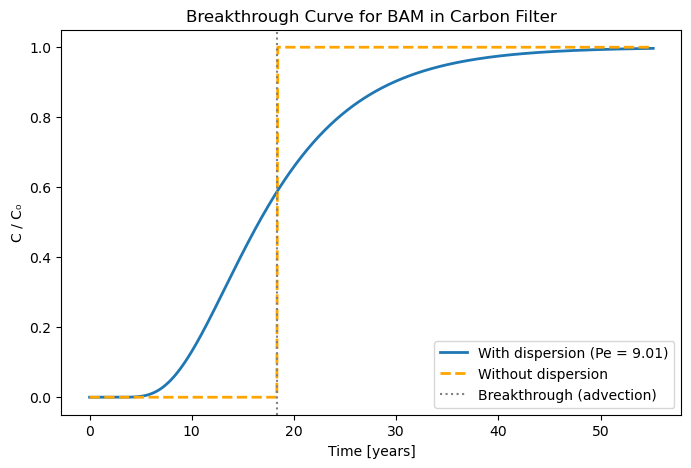

In [26]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import erfc

# Constants
R = 966001          # retardation factor
vp = 23.24165       # seepage velocity [m/h]
H = 3.8746          # filter height [m]
D = 10              # dispersion coefficient [m2/h]
C0 = 1              # dimensionless concentration

# Calculate
Pe = (vp * H) / D
t_breakthrough = (R * H) / vp  # [h]
print(f"Péclet number = {Pe:.2f}")
print(f"Breakthrough time t_s = {t_breakthrough/24/365:.2f} years")

# t-axis
t_vals = np.linspace(0, t_breakthrough * 3, 600)  # 50% longer than breakthrough
theta_R = (vp * t_vals) / (H * R)                 # dimensionless time (retardation included)

# Dispersion model (Eq. 6.24)
def F_xt(Pe, theta_R):
    term1 = 0.5 * erfc((1 - theta_R) / (2 * np.sqrt(theta_R / Pe)))
    term2 = 0.5 * np.exp(Pe) * erfc((1 + theta_R) / (2 * np.sqrt(theta_R / Pe)))
    return term1 + term2

C_disp = F_xt(Pe, theta_R) * C0

# Without dispersion - only advection
C_adv = np.zeros_like(t_vals)
C_adv[t_vals >= t_breakthrough] = C0

# Plot
plt.figure(figsize=(8,5))
plt.plot(t_vals/24/365, C_disp, label=f"With dispersion (Pe = {Pe:.2f})", linewidth=2)
plt.plot(t_vals/24/365, C_adv, '--', label="Without dispersion", color='orange', linewidth=2)
plt.axvline(t_breakthrough/24/365, color='gray', linestyle=':', label="Breakthrough (advection)")

plt.xlabel("Time [years]")
plt.ylabel("C / C₀")
plt.title("Breakthrough Curve for BAM in Carbon Filter")
plt.legend()
plt.show()

In [27]:
C_out = 0.1 #limit value ug/L
C_0 = 1 #mg/L
C_BAM_MAX = 0.4 #ug/L

breakthrough_ratio = C_out / C_BAM_MAX
print(f"Breakthrough Ratio: {breakthrough_ratio}")


Breakthrough Ratio: 0.25


Péclet number = 9.01
Advection breakthrough time ≈ 18.38 years
Breakthrough ratio = 0.25
Breakthrough time (with dispersion) = 12.22 years


C:\Users\mtloo\AppData\Local\Temp\ipykernel_23572\392259009.py:30: RuntimeWarning: divide by zero encountered in divide
  term1 = 0.5 * erfc((1 - theta_R) / (2 * np.sqrt(theta_R / Pe)))
C:\Users\mtloo\AppData\Local\Temp\ipykernel_23572\392259009.py:31: RuntimeWarning: divide by zero encountered in divide
  term2 = 0.5 * np.exp(Pe) * erfc((1 + theta_R) / (2 * np.sqrt(theta_R / Pe)))


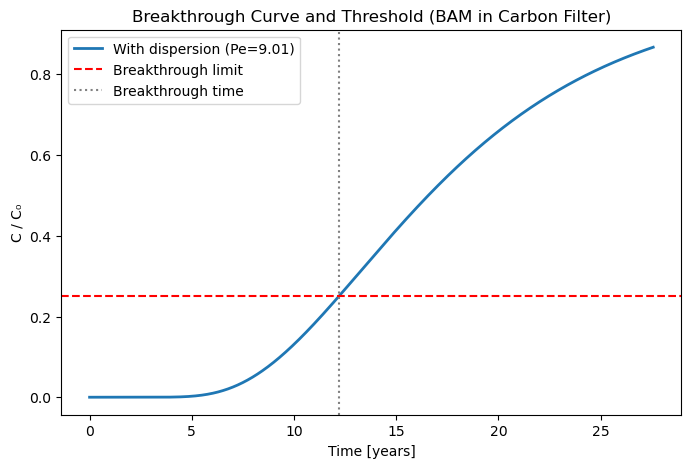

In [28]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import erfc

# Constants
R = 966001
vp = 23.24165       # m/h
H = 3.8746          # m
D = 10              # m²/h
C0 = 1.0

# Equations
Pe = (vp * H) / D
t_breakthrough_adv = (R * H) / vp  # [h]
print(f"Péclet number = {Pe:.2f}")
print(f"Advection breakthrough time ≈ {t_breakthrough_adv/24/365:.2f} years")

# Breakthrough Limit
C_out = 0.1 #limit value ug/L
C_BAM_MAX = 0.4 #ug/L
breakthrough_ratio = C_out / C_BAM_MAX
print(f"Breakthrough ratio = {breakthrough_ratio:.2g}")

# t-axis
t_vals = np.linspace(0, t_breakthrough_adv * 1.5, 800)
theta_R = (vp * t_vals) / (H * R)

# Dispersion model
def F_xt(Pe, theta_R):
    term1 = 0.5 * erfc((1 - theta_R) / (2 * np.sqrt(theta_R / Pe)))
    term2 = 0.5 * np.exp(Pe) * erfc((1 + theta_R) / (2 * np.sqrt(theta_R / Pe)))
    return term1 + term2


C_disp = F_xt(Pe, theta_R)

# Find t where limit is first exceeded
indices = np.where(C_disp >= breakthrough_ratio)[0]

if len(indices) > 0:
    t_breakthrough_disp = t_vals[indices[0]]
    print(f"Breakthrough time (with dispersion) = {t_breakthrough_disp/24/365:.2f} years")
else:
    print("Breakthrough not reached within simulation time.")

# Plot
plt.figure(figsize=(8,5))
plt.plot(t_vals/24/365, C_disp, label=f"With dispersion (Pe={Pe:.2f})", linewidth=2)
plt.axhline(breakthrough_ratio, color='red', linestyle='--', label='Breakthrough limit')
plt.axvline(t_breakthrough_disp/24/365, color='gray', linestyle=':', label='Breakthrough time')
plt.xlabel("Time [years]")
plt.ylabel("C / C₀")
plt.title("Breakthrough Curve and Threshold (BAM in Carbon Filter)")
plt.legend()
plt.show()

---

### E) Precipitation In The Carbon Filter

$\bold{For \ Activity \ Factor \ 1}$

In [29]:
import math
from sympy import symbols, Eq, nsolve, N

# --- Define symbols ---
CO32, HCO3, H, OH = symbols('CO32 HCO3 H OH', positive=True, real=True)

# --- Constants ---
K1 = 10**-6.3
K2 = 10**-10.3
Ksp = 10**-8.36  # at 10°C
Kw = 10**-14
P_CO2 = 420 * 9 * 10**-6  # from ppm to atm (9x oversaturation)
TAL = 4.61e-3  # mol/L (converted from 4.61 meq/L)

#[H2CO3] = [CO2] --> because of equilibrium in the system
#H2CO3 = KH(CO2) * P_CO2
H2CO3 = 0.034 * P_CO2  # Henry's law: [H2CO3] = KH * P_CO2

# --- Equations ---
eq1 = Eq(K1, H * HCO3 / H2CO3)               # first dissociation
eq2 = Eq(K2, H * CO32 / HCO3)                # second dissociation
eq3 = Eq(Kw, H * OH)                         # water equilibrium
eq4 = Eq(TAL, 2*CO32 + HCO3 + OH - H)        # alkalinity balance

# Initial guess
guess = (1e-7, 1e-3, 1e-6, 1e-7)

# Solve
solution = nsolve((eq1, eq2, eq3, eq4), (H, HCO3, CO32, OH), guess)


# Results
H_val, HCO3_val, CO3_val, OH_val = map(float, solution)
pH_val = -math.log10(H_val)


print(f"[H+]     = {H_val:.3e} M")
print(f"[HCO3-]  = {HCO3_val:.3e} M")
print(f"[CO3--]  = {CO3_val:.3e} M")
print(f"[OH-]    = {OH_val:.3e} M")
print(f"[H2CO3]  = {H2CO3:.3e} M")
print(f"pH       = {pH_val:.2f}")

[H+]     = 1.407e-08 M
[HCO3-]  = 4.577e-03 M
[CO3--]  = 1.630e-05 M
[OH-]    = 7.105e-07 M
[H2CO3]  = 1.285e-04 M
pH       = 7.85


Ion-Product for Activity Coefficent = 1:

$$ IP = [Ca^{2+}][CO3^{2-}] $$

In [30]:
# ion product
Ca = 94*10**-3/40.08 #mg/L --> mol/L
ion_product = Ca * CO3_val
print(f"Ion product = {ion_product:.2e}")

Ksp_CaCO3 = 10**(-8.36) #Ksp for CaCO3 at 10 degrees celcius

print(ion_product > Ksp_CaCO3) # if ion product > Ksp precipitation will occur

Ion product = 3.82e-08
True


___

$ \bold{For \ Activity \ Factor < 1}  $

In [31]:
conductivity = 61*10**3*10**-2 #mS/m --> uS/cm
print(f"Conductivity = {conductivity:.2f} uS/cm")

Conductivity = 610.00 uS/cm


With known conductivity the activity coefficients $\gamma_1$ and $\gamma_2$ can be read in Figure 1.1 in Compendium

In [32]:
import math
from sympy import symbols, Eq, nsolve, N

# Read in figure 1.1 in Compendium
gamma1 = 0.95
gamma2 = 0.75

# Define symbols
CO32, HCO3, H, OH = symbols('CO32 HCO3 H OH', positive=True, real=True)

# Constants
K1 = 10**-6.3
K2 = 10**-10.3
Ksp = 10**-8.36  # at 10°C
Kw = 10**-14
P_CO2 = 420 * 9 * 10**-6  # from ppm to atm (9x oversaturation)
TAL = 4.61e-3  # mol/L (converted from 4.61 meq/L)

# [H2CO3] = [CO2] --> because of equilibrium in the system
# H2CO3 = KH(CO2) * P_CO2
H2CO3 = 0.034 * P_CO2  # Henry's law: [H2CO3] = KH * P_CO2

# Equations
eq1 = Eq(K1, (gamma1 * H) * (gamma1 * HCO3) / (gamma1* H2CO3))               # first dissociation
eq2 = Eq(K2, (gamma1 * H) * (gamma2 * CO32) / (gamma1 * HCO3))               # second dissociation
eq3 = Eq(Kw, gamma1**2 * H * OH)                                             # water equilibrium
eq4 = Eq(TAL, 2* gamma2 * CO32 + gamma1 * HCO3 + gamma1* OH - gamma1* H)     # alkalinity balance

# Initial guess
guess = (1e-8, 1e-3, 1e-6, 1e-6)

solution = nsolve((eq1, eq2, eq3, eq4), (H, HCO3, CO32, OH), guess)


# results
H_val, HCO3_val, CO3_val, OH_val = map(float, solution)
pH_val = -math.log10(H_val)

print(f"[H+]     = {H_val:.3e} M")
print(f"[HCO3-]  = {HCO3_val:.3e} M")
print(f"[CO3--]  = {CO3_val:.3e} M")
print(f"[OH-]    = {OH_val:.3e} M")
print(f"[H2CO3]  = {H2CO3:.3e} M")
print(f"pH       = {pH_val:.2f}")

[H+]     = 1.408e-08 M
[HCO3-]  = 4.816e-03 M
[CO3--]  = 2.286e-05 M
[OH-]    = 7.870e-07 M
[H2CO3]  = 1.285e-04 M
pH       = 7.85


Ion-Product for Activity Coefficient < 1:
$$IP = \gamma_2 [Ca^{2+}] \gamma_2 [CO_3^{-2} ]$$

In [33]:
ion_product = gamma2 * Ca * gamma2 * CO3_val
print(f"Ion product = {ion_product:.3e}")

Ksp_CaCO3 = 10**(-8.36) # Ksp for CaCO3 at 10 degrees celcius

print(ion_product > Ksp_CaCO3) # if ion product > Ksp then precipitation will occur

Ion product = 3.015e-08
True


___

### F) Oxidation of $Fe^{2+}$ and Precipitation of $Fe^{3+}$

##### Oxidation:

$$ 4Fe^{2+} + O_2 + 4H^+ \rightarrow 4Fe^{3+} + 2H_2O $$

##### Precipitation:

$$ 4Fe^{3+} + 12H_2O \rightarrow 4Fe(OH)_3 + 12H^+ $$

##### Combined:

$12H_2O - 2H_2O = 10H_2O$

$12H^+ - 4H^+ = 8H^+$

$$ 4Fe^{2+} + O_2 + 10H_2O \rightarrow 4Fe(OH)_3 + 8H^+$$

___

### G) Reactors Iron Filtration Efficency

In [34]:
k1 = 1 #1/min
res_time = 13 #min
max_conc = 200 #µg/L
t = np.log(2)/k1

iron_C_in = 6e3 #µg/L

CMFR_ratio = 1/(1+k1*res_time)
PFR_ratio = exp(-k1*res_time).evalf()

C_out_CMFR = CMFR_ratio*iron_C_in #µg/L
C_out_CMFR_series = C_out_CMFR*CMFR_ratio #µg/L
C_out_PFR = PFR_ratio*iron_C_in #µg/L

print(f"C_Out CMFR: {C_out_CMFR:.2f} µg/L"),
print(f"C_Out CMFR in series: {C_out_CMFR_series:.2f} µg/L"),
print(f"C_Out PFR: {C_out_PFR:.2g} µg/L")

C_Out CMFR: 428.57 µg/L
C_Out CMFR in series: 30.61 µg/L
C_Out PFR: 0.014 µg/L


In [35]:
Fe_data = pd.DataFrame ({
    'Reactor Design' : ['CMFR', 'CMFR in Series', 'PFR'],
    'Output Iron Conc.' : [C_out_CMFR, C_out_CMFR_series, C_out_PFR],
    'Unit' : ['µg/L', 'µg/L', 'µg/L'],
    'Below Conc. Limit' : [(C_out_CMFR < max_conc), (C_out_CMFR_series < max_conc), (C_out_PFR < max_conc)]
})

Fe_data

,Reactor Design,Output Iron Conc.,Unit,Below Conc. Limit
0,CMFR,428.571429,µg/L,False
1,CMFR in Series,30.612245,µg/L,True
2,PFR,0.0135619764418863,µg/L,True


___

## 3. New Abstraction Well

### A) Completed Water Analysis

In [36]:
import pandas as pd

import pandas as pd

data = {
    "Ca2+":   {"mg/L": 210, "g/mol": 40.078,  "charge":  2},
    "Mg2+":   {"mg/L": 37,  "g/mol": 24.305,  "charge":  2},
    "Na+":    {"mg/L": 50,  "g/mol": 22.990,  "charge":  1},
    "K+":     {"mg/L": 15,  "g/mol": 39.0983, "charge":  1},
    "Fe2+":   {"mg/L": 2,   "g/mol": 55.850,  "charge":  2},
    "NH4+":   {"mg/L": 1,   "g/mol": 18.050,  "charge":  1},
    "HCO3-":  {"mg/L": 385, "g/mol": 61.020,  "charge": -1},
    "Cl-":    {"mg/L": 200, "g/mol": 35.450,  "charge": -1},
    "SO4^2-": {"mg/L": 205, "g/mol": 96.070,  "charge": -2},
    "NO3-":   {"mg/L": 2.6, "g/mol": 62.0049, "charge": -1},
}

df = pd.DataFrame(data).T

df["mg/mol"]  = df["g/mol"] * 1000                    # mg per mmol basis helper
df["mmol/L"]  = df["mg/L"] / df["g/mol"]              # mg/L ÷ g/mol
df["meq/L"]   = df["mmol/L"] * abs(df["charge"])      # charge × mmol/L

df


,mg/L,g/mol,charge,mg/mol,mmol/L,meq/L
Ca2+,210.0,40.0780,2.0,40078.0,5.239782,10.479565
Mg2+,37.0,24.3050,2.0,24305.0,1.522321,3.044641
Na+,50.0,22.9900,1.0,22990.0,2.174859,2.174859
K+,15.0,39.0983,1.0,39098.3,0.383648,0.383648
Fe2+,2.0,55.8500,2.0,55850.0,0.035810,0.071620
NH4+,1.0,18.0500,1.0,18050.0,0.055402,0.055402
HCO3-,385.0,61.0200,-1.0,61020.0,6.309407,6.309407
Cl-,200.0,35.4500,-1.0,35450.0,5.641749,5.641749
SO4^2-,205.0,96.0700,-2.0,96070.0,2.133861,4.267721
NO3-,2.6,62.0049,-1.0,62004.9,0.041932,0.041932


In [37]:
sum_cations = df[df["charge"] > 0]["meq/L"].sum()
sum_anions  = df[df["charge"] < 0]["meq/L"].sum()
print(f"Sum of Cations: {sum_cations:.2f}")
print(f"Sum of Anions: {sum_anions:.2f}")

EN = (sum_cations - sum_anions) / (sum_cations + sum_anions)
print(f"EN: {EN:.4f} %")

Sum of Cations: 16.21
Sum of Anions: 16.26
EN: -0.0016 %


___

### B) Water Hardness

In [38]:
hardness_Ca = df.loc["Ca2+", "mg/L"] * df.loc["Ca2+", "meq/L"]
hardness_Mg = df.loc["Mg2+", "mg/L"] * df.loc["Mg2+", "meq/L"]

hardness_tot = df.loc[['Ca2+', 'Mg2+'], 'meq/L'].sum()
print(f"Total Hardness: {hardness_tot:.2f} meq/L")

dh_convert = 2.8 #meq/L per dh

dh = hardness_tot * dh_convert
print(f"dh: {dh:.2f}")

Total Hardness: 13.52 meq/L
dh: 37.87
